# Uçtan Uca Pipeline Demo — CLIP ile Metin-Görsel Arama

Bu notebook, `src/` altındaki script'leri tek tek çalıştırmadan tüm akışı (veri → CLIP embedding → FAISS index → metin/görsel sorgusu → sonuç) tek bir yerde gösterir.

Önkoşul: `python src/prepare_data.py && python src/embed.py && python src/index.py` bir kere çalıştırılmış olmalı (bu notebook, önceden hesaplanmış embedding/index dosyalarını okur — CLIP'i 10.000 görsel üzerinde yeniden çalıştırmaz).

In [ ]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..") / "src"))

import json
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

from search import ClipSearchEngine

PROJECT_ROOT = Path("..")
IMAGES_DIR = PROJECT_ROOT / "data" / "processed" / "images"
INDEX_PATH = PROJECT_ROOT / "outputs" / "faiss_index" / "image_index.faiss"

C:\Users\ibrahim\anaconda3\envs\yolov8_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Veri seti önizlemesi

In [ ]:
prompts = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "prompts.csv")
print(f"Toplam gorsel: {len(prompts)}")
prompts.head()

Toplam gorsel: 10000


,image_id,filename,prompt
0,0,00000.jpg,green cactus under white sky during daytime
1,1,00001.jpg,white and black dogs on snow covered ground du...
2,2,00002.jpg,fawn pug in black and gray backpack
3,3,00003.jpg,grayscale photography of land under white clouds
4,4,00004.jpg,calm body of water and mountain


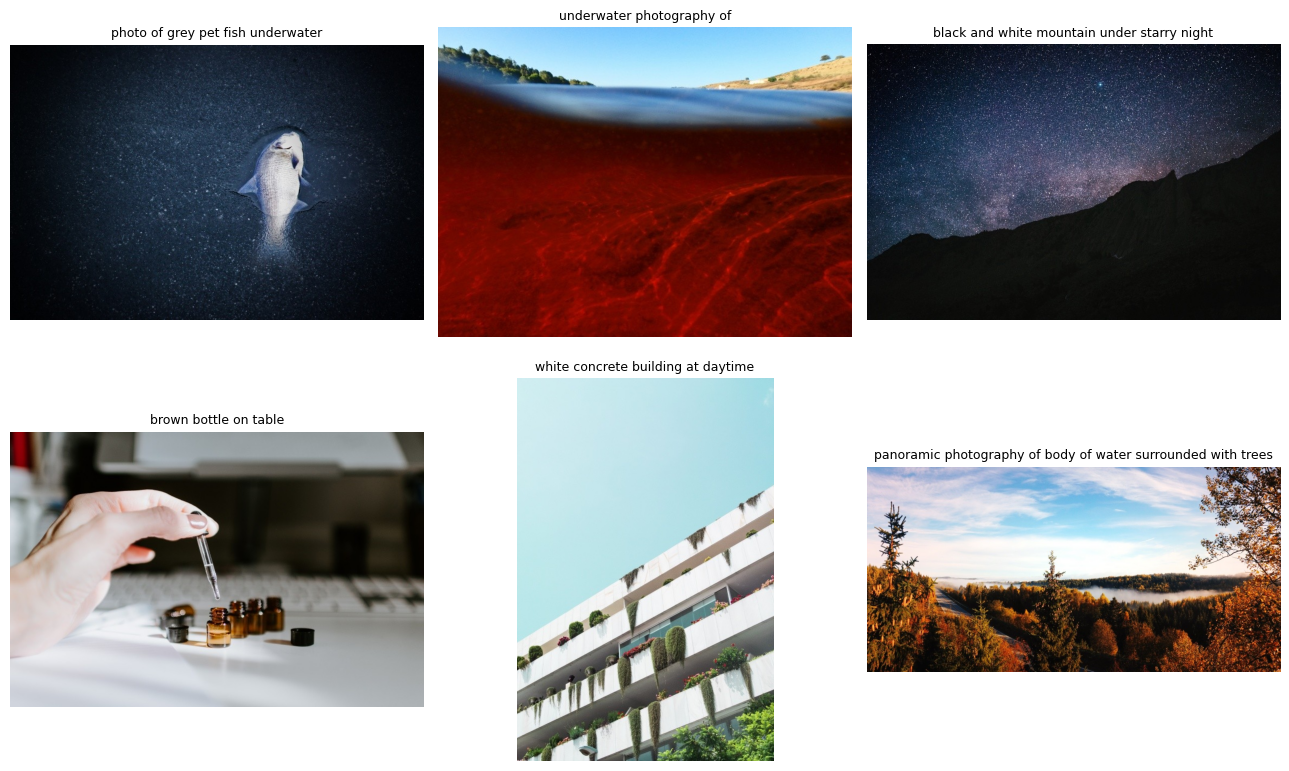

In [ ]:
sample = prompts.sample(6, random_state=42)
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    img = Image.open(IMAGES_DIR / row["filename"])
    ax.imshow(img)
    ax.set_title(row["prompt"], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. CLIP arama motorunu yükle

`ClipSearchEngine` (bkz. `src/search.py`), CLIP modelini + önceden hesaplanmış FAISS index'i yükler.

In [ ]:
engine = ClipSearchEngine(index_path=str(INDEX_PATH))
print(f"Index boyutu: {engine.index.ntotal} vektor")


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 14051.62it/s]

Index boyutu: 10000 vektor


## 3. Metin sorgusuyla arama

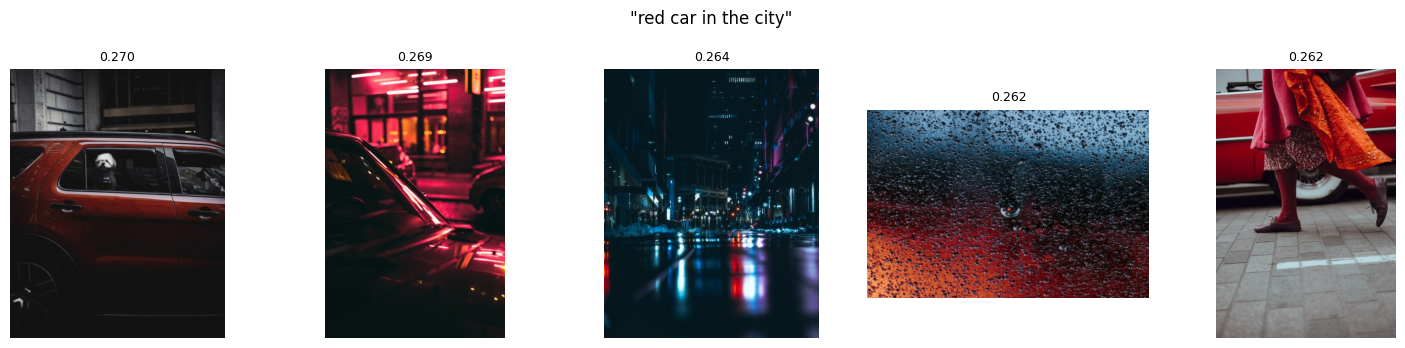

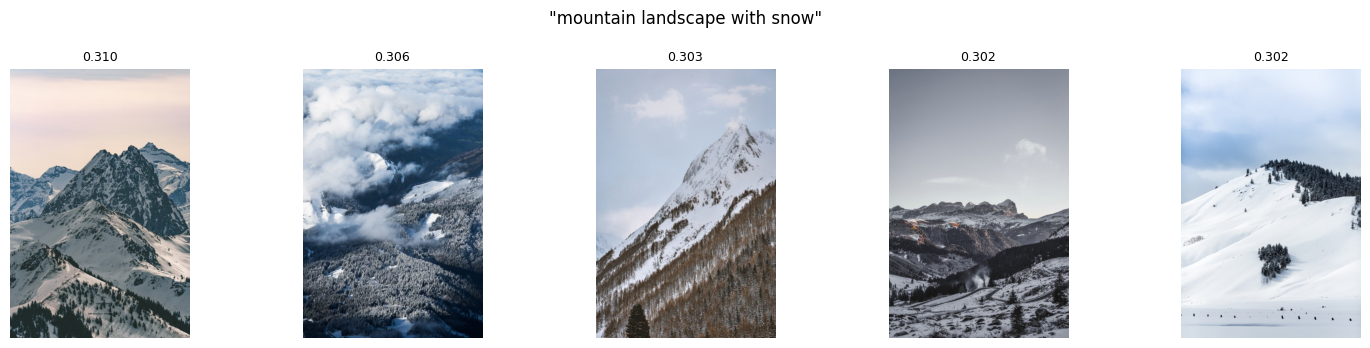

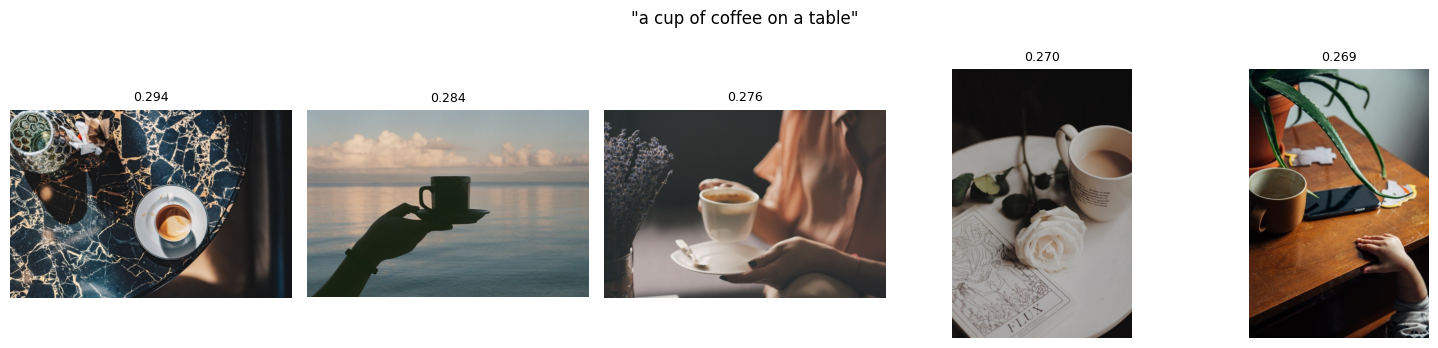

In [ ]:
def show_results(results, title=""):
    fig, axes = plt.subplots(1, len(results), figsize=(3 * len(results), 3.5))
    if title:
        fig.suptitle(title)
    for ax, r in zip(axes, results):
        img = Image.open(IMAGES_DIR / r["filename"])
        ax.imshow(img)
        ax.set_title(f"{r['score']:.3f}", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


queries = [
    "red car in the city",
    "mountain landscape with snow",
    "a cup of coffee on a table",
]
for q in queries:
    results = engine.search_by_text(q, k=5)
    show_results(results, title=f'"{q}"')

## 4. Bonus: görsel-ile-görsel arama (image-to-image)

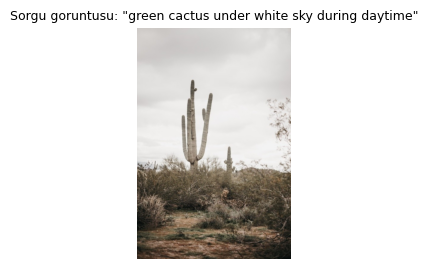

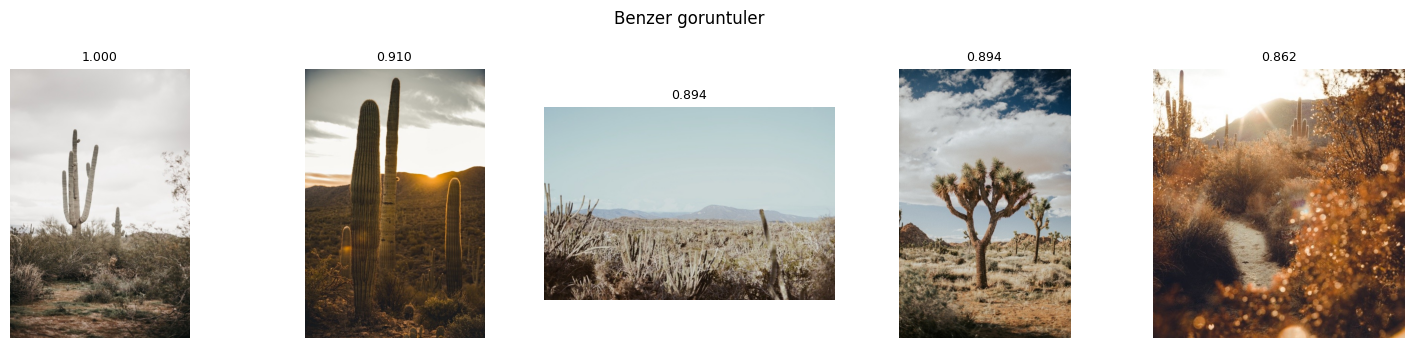

In [ ]:
query_row = prompts.iloc[0]
query_image = Image.open(IMAGES_DIR / query_row["filename"])

results = engine.search_by_image(query_image, k=5)

plt.figure(figsize=(3, 3))
plt.imshow(query_image)
plt.title(f"Sorgu goruntusu: \"{query_row['prompt']}\"", fontsize=9)
plt.axis("off")
plt.show()

show_results(results, title="Benzer goruntuler")

## 5. Retrieval değerlendirmesi (Recall@k)

`src/evaluate_retrieval.py` her prompt'u sorgu olarak kullanıp kendi görselini top-k'ta bulma oranını (Recall@1/5/10) ölçüyor — sonuçlar önceden hesaplanmış olmalı (`python src/evaluate_retrieval.py`).

In [ ]:
eval_path = PROJECT_ROOT / "outputs" / "predictions" / "retrieval_eval.json"
if eval_path.exists():
    with open(eval_path, encoding="utf-8") as f:
        print(json.dumps(json.load(f), indent=2))
else:
    print(f"Henuz hesaplanmamis: once `python src/evaluate_retrieval.py` calistirin.")

{
  "n_queries": 10000,
  "recall@1": 0.1214,
  "recall@5": 0.2745,
  "recall@10": 0.3644
}


## Özet

Bu notebook, `prepare_data.py → embed.py → index.py` ile hazırlanan veri/embedding/index üzerinden CLIP tabanlı metin→görsel ve görsel→görsel aramanın uçtan uca nasıl çalıştığını gösterdi. Model açıklanabilirliği (Grad-CAM ile "model görselin neresine bakarak eşleşme kurdu") için `explainability.ipynb`'ye bakın.